**← Previous:** [Drift](11_drift.ipynb)  

```text
Capital analysis
├── Import & Setup
├── PD and LGD estimation
└── Stress-testing        
```

#### Import & Setup 

In [1]:
# Init work dir

from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
# Standard modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Framework

from src.decisioning import estimate_reverse_capital_stress, run_reverse_capital_stress_seeds, show_pd_stress_vs_capital, show_pd_stress_vs_lossdev, ec_summary, show_experiment_comparison
from src.feature_engineering import create_target_def12
from src.modelling import apply_pipe_PD, apply_pipe_LGD
from src.preprocessing import input_load, make_homogeneous_portfolio
from src.validation import validate_predictions

# Dataset specific settings

from src import settings_dataset_unsecured as settings

# Configuration

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.expand_frame_repr", False)
from sklearn import set_config; set_config(transform_output="pandas")

In [3]:
# load input file

portfolio = input_load(2019, 2020, column_date=settings.COLUMN_DATE, column_year=settings.COLUMN_YEAR)
portfolio, dr_summary = create_target_def12(portfolio, 
                                            settings.COLUMN_DATE,
                                            settings.COLUMN_YEAR, 
                                            settings.COLUMN_TARGET_DATE,
                                            settings.COLUMN_TARGET, 
                                            verbose=False,
                                            )

#### PD and LGD estimation

In [4]:
# import pipelines

import joblib
pipeline_pd  = joblib.load("../models/PIPELINE_PD_v012_LR_cal_shift-test.pkl")
pipeline_lgd = joblib.load("../models/PIPELINE_LGD_v012_amount.pkl")

In [5]:
# apply pipelines

portfolio = apply_pipe_PD(portfolio, pipeline_pd)
portfolio = apply_pipe_LGD(portfolio, pipeline_lgd)

In [6]:
# validate model output

validate_predictions(portfolio)

----------------------------------------
MODEL OUTPUT VALIDATION
----------------------------------------


,PD,LGD
Min,0.000,0.000
Mean,0.150,0.132
Max,0.595,0.224
NaNs,0.000,0.000


,PD,LGD
Min,2.284632e-18,0.000000
Mean,1.499553e-01,0.132040
Max,5.948402e-01,0.224033
NaNs,0.000000e+00,0.000000


## Stress-testing

#### 1st experiment

In [7]:
# how much should we stress PDs 
# to exceed an economic capital constraint?

pd_stress_factors = np.round(np.arange(1.0, 5.1, 0.1), 1)
capital_stress = estimate_reverse_capital_stress(portfolio, 
                                                 threshold=0.20, 
                                                 stress_factors=pd_stress_factors,
                                                 column_lgd='LossGivenDefault',
                                                 column_def=settings.COLUMN_TARGET,
                                                 column_ead=settings.COLUMN_EAD,
                                                 verbose=False)
capital_stress.to_pickle("../archive/reverse_capital_stress_1.pkl")

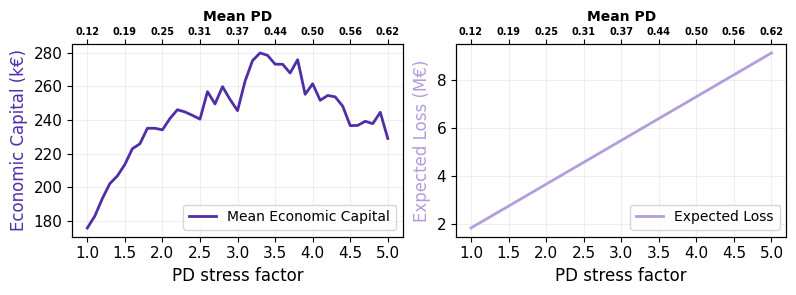

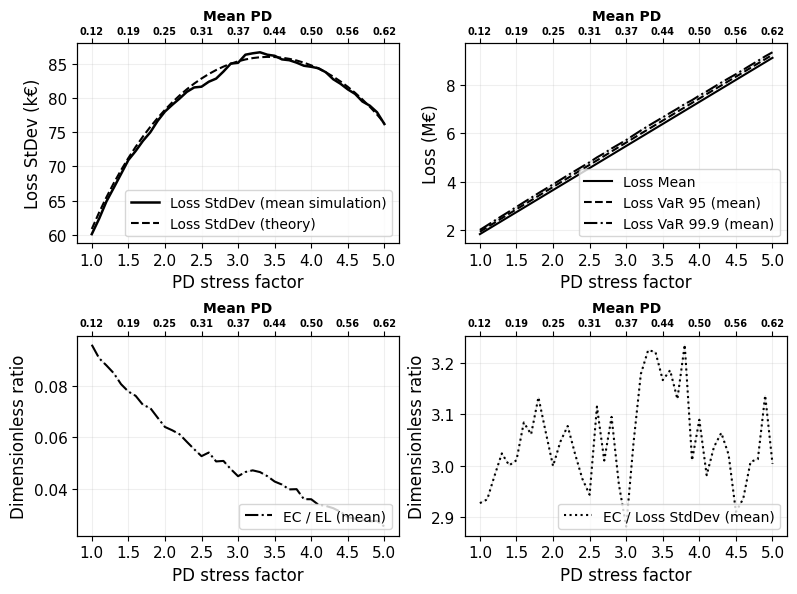


========== MONTE CARLO STRESS SUMMARY ==========

Number of seeds:             1
Stress scenarios:            41

--- Expected Loss ---
Baseline EL:                 €1,825,808
Final EL:                    €9,129,041
EL increase:                 400.0%

--- Economic Capital ---
Baseline EC:                 €175,808
Maximum mean EC:             €279,791
Peak stress factor:          3.3x
Final EC:                    €228,955
EC change from peak:         -18.2%

--- VaR 99.9% ---
Baseline VaR:                €2,001,557
Final VaR:                   €9,358,384
Baseline VaR CV:             nan%
Final VaR CV:                nan%

--- EC variability ---
Baseline EC CV:              nan%
Peak EC CV:                  nan%




In [7]:
# load and show results

capital_stress = pd.read_pickle("../archive/reverse_capital_stress_1.pkl")
show_1 = show_pd_stress_vs_capital(capital_stress, show_plot=True, invert_y=False)
show_2 = show_pd_stress_vs_lossdev(capital_stress, show_plot=True, invert_y=False)
summary = ec_summary(capital_stress, print_table=False)

#### Seeds experiment

In [ ]:
# Does the result remain consistent with different seeds?
# (runtime is 40m for 5 seeds)

pd_stress_factors = np.round(np.arange(1.0, 5.1, 0.1), 1)
seeds = [42, 123, 456, 789, 2026, 17, 83, 256, 512, 1024, 1337, 2025, 3141, 2718, 9001, 111, 222, 333, 444, 555, 678, 987, 1234, 5678, 8765]
results_all = run_reverse_capital_stress_seeds(portfolio, 
                                               threshold=0.20, 
                                               stress_factors=pd_stress_factors,
                                               column_lgd='LossGivenDefault',
                                               column_def=settings.COLUMN_TARGET,
                                               column_ead=settings.COLUMN_EAD, 
                                               seeds=seeds)
results_all.to_pickle("../archive/reverse_capital_stress_25seeds.pkl")

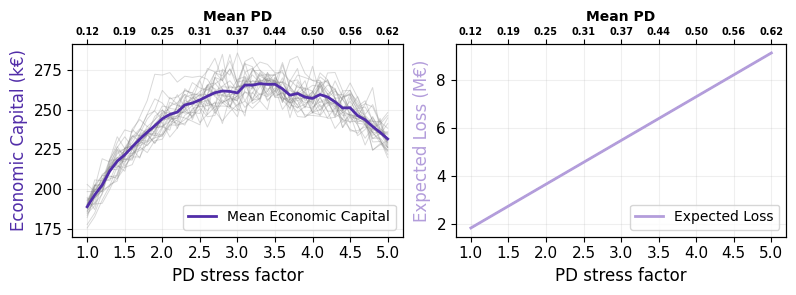

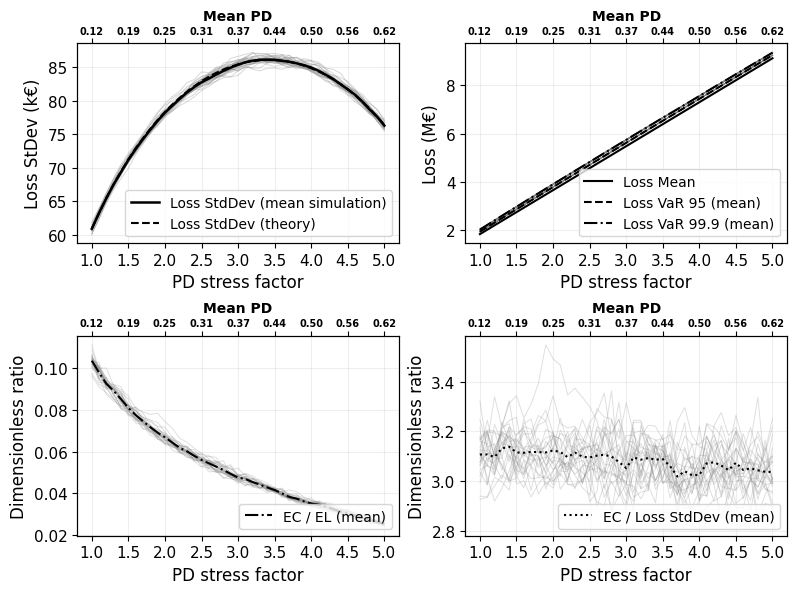


========== MONTE CARLO STRESS SUMMARY ==========

Number of seeds:             25
Stress scenarios:            41

--- Expected Loss ---
Baseline EL:                 €1,825,808
Final EL:                    €9,129,041
EL increase:                 400.0%

--- Economic Capital ---
Baseline EC:                 €189,105
Maximum mean EC:             €266,268
Peak stress factor:          3.3x
Final EC:                    €231,619
EC change from peak:         -13.0%

--- VaR 99.9% ---
Baseline VaR:                €2,015,026
Final VaR:                   €9,360,509
Baseline VaR CV:             0.30%
Final VaR CV:                0.08%

--- EC variability ---
Baseline EC CV:              3.07%
Peak EC CV:                  2.53%




In [8]:
# load and show results

results_all = pd.read_pickle("../archive/reverse_capital_stress_25seeds.pkl")
show_1 = show_pd_stress_vs_capital(results_all, show_plot=True, invert_y=False)
show_2 = show_pd_stress_vs_lossdev(results_all, show_plot=True, invert_y=False)
summary = ec_summary(results_all, print_table=False)

#### Homogeneous experiment

In [13]:
# make LGD and EAD homogeneous (under the PD threshold)

portfolio = make_homogeneous_portfolio(
    df=portfolio,
    ead_col="Amount",
    lgd_col="LossGivenDefault",
    pd_threshold=0.20,
    ead_result_col="Amount_hom",
    lgd_result_col="LossGivenDefault_hom"
)

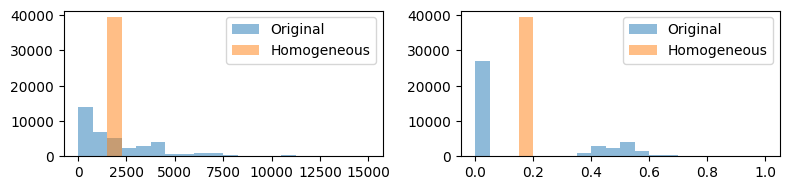

In [14]:
# check

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 2))

bins_ead = np.linspace(0, 15000, 21)
bins_lgd = np.linspace(0, 1, 21)

axes[0].hist(portfolio["Amount"], bins=bins_ead, alpha=0.5, label="Original")
axes[0].hist(portfolio["Amount_hom"], bins=bins_ead, alpha=0.5, label="Homogeneous")

axes[1].hist(portfolio["LossGivenDefault"], bins=bins_lgd, alpha=0.5, label="Original")
axes[1].hist(portfolio["LossGivenDefault_hom"], bins=bins_lgd, alpha=0.5, label="Homogeneous")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Does EC show similar behaviour when PD and LGD are homogeneous?

pd_stress_factors = np.round(np.arange(1.0, 5.1, 0.1), 1)
seeds = [42, 123, 456, 789, 2026, 17, 83, 256, 512, 1024, 1337, 2025, 3141, 2718, 9001, 111, 222, 333, 444, 555, 678, 987, 1234, 5678, 8765]
results_hom = run_reverse_capital_stress_seeds(portfolio, 
                                               threshold=0.20, 
                                               stress_factors=pd_stress_factors,
                                               column_lgd="LossGivenDefault_hom",
                                               column_def=settings.COLUMN_TARGET,
                                               column_ead="Amount_hom", 
                                               seeds=seeds)
results_hom.to_pickle("../archive/reverse_capital_stress_25seeds_hom.pkl")

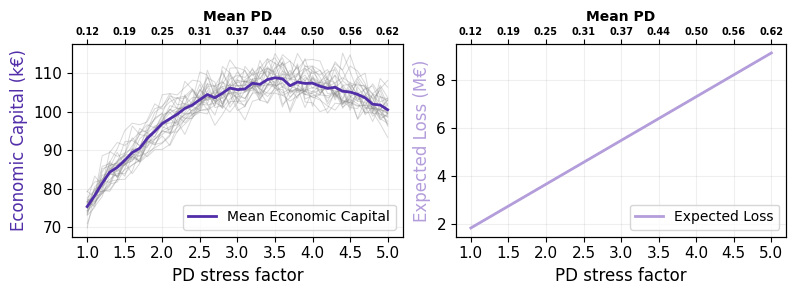

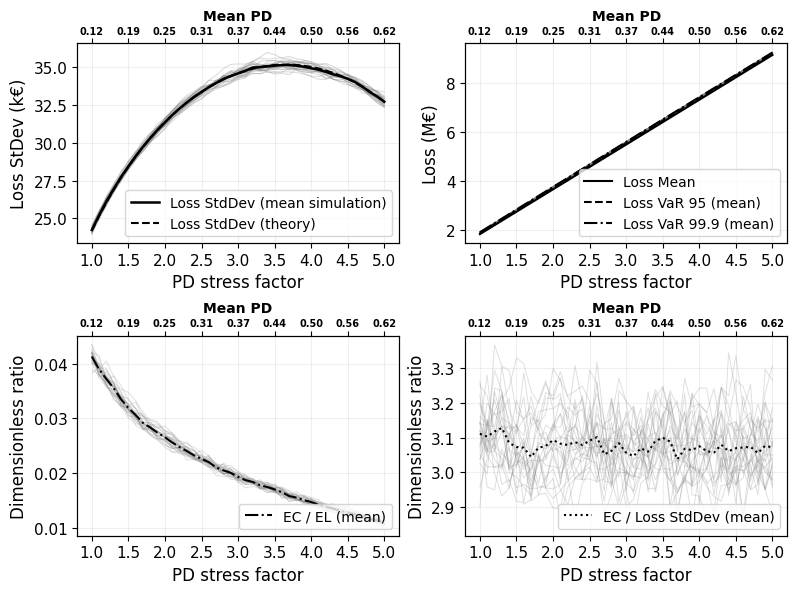


========== MONTE CARLO STRESS SUMMARY ==========

Number of seeds:             25
Stress scenarios:            41

--- Expected Loss ---
Baseline EL:                 €1,825,808
Final EL:                    €9,129,041
EL increase:                 400.0%

--- Economic Capital ---
Baseline EC:                 €75,391
Maximum mean EC:             €108,848
Peak stress factor:          3.5x
Final EC:                    €100,541
EC change from peak:         -7.6%

--- VaR 99.9% ---
Baseline VaR:                €1,901,287
Final VaR:                   €9,229,532
Baseline VaR CV:             0.12%
Final VaR CV:                0.04%

--- EC variability ---
Baseline EC CV:              2.98%
Peak EC CV:                  2.59%




In [11]:
# load and show results

results_hom = pd.read_pickle("../archive/reverse_capital_stress_25seeds_hom.pkl")
show_1 = show_pd_stress_vs_capital(results_hom, show_plot=True, invert_y=False)
show_2 = show_pd_stress_vs_lossdev(results_hom, show_plot=True, invert_y=False)
summary = ec_summary(results_hom, print_table=False)

#### Comparison

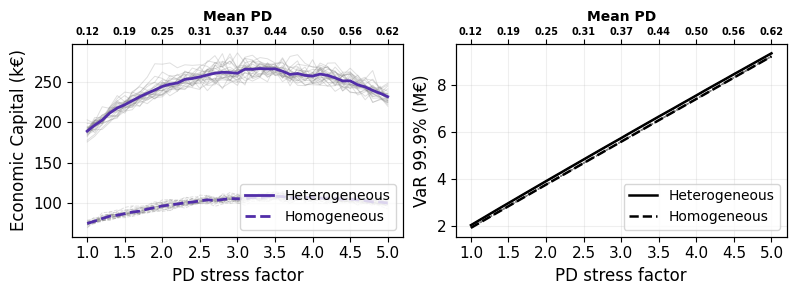

In [10]:
fig = show_experiment_comparison(
       table_heterogeneous=results_all,
       table_homogeneous=results_hom,
       invert_y=False
    )